# Advanced trace features: candidate inputs for an ML model

**Purpose.** This notebook collects features of a raw trace that an ML model **might** pick up as
signs of the read noise σe, the dark current λ or the gain. We do **not** try to compute σe, λ or the
gain from the trace here. The model learns any connection from the training packets, where the
image gives the labels. A feature is worth keeping if:

1. it is well defined and can be computed automatically from every trace;
2. it is stable between repeats at the same settings (section F tests this);
3. it is plausibly connected to something that affects the image. The scan will show whether it
   actually responds to the operating parameters.

**Each section shows:**

* **Feature**: what it is, and whether it is a number or a curve;
* **How**: a short function, applied to one real trace (module 101, channel 0, 2026-10-08, first
  repeat), with a plot;
* **Why a model might use it**: the physical reason it could carry information.

The functions are defined in the notebook so every line is visible. The ones we keep can later move
into a module (e.g. `src/trace_features.py`) and into `process_packet.py`, so every packet's 6 trace
sets get them, with their run-to-run scatter.

**Contents**

* A. Features of the CDS level: common pattern, pixel-to-pixel spread, charge loss
* B. Noise character: autocorrelation, Allan deviation, CDS spectrum, reset scatter and band powers, window length, settling, baseline coupling
* C. Discrete noise: steps, outliers, interference lines, ADC codes
* D. Edges: timing jitter, sub-sample waveform, recovery after the pulse, feedthrough per volt, variation along the cycle
* E. Slow structure: row-start recovery, drift, horizontal transfers, principal components
* F. Which features separate two amplifiers better than repeats, and the feature vector a model would get

In [1]:
import sys, json, itertools
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt

PROJECT = Path.cwd().parent
sys.path.insert(0, str(PROJECT / "src"))
from decode_trace import decode_trace, SAMPLE_RATE_HZ
from trace_regions import split_regions
from compare_trace import usable_pixels, row_start_pixels, fit_exponential

plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3})
SESSION = PROJECT / "data" / "2026-10-08-PA03_PQ04_traces"
def traces_of(ch, board=101):
    return sorted(SESSION.glob(f"trace_*_ch{ch}_{board}_*.RJ45ADCDATA{ch}"))

PATH = traces_of(0)[0]
trace = decode_trace(PATH)
regions = split_regions(trace)
meta = json.loads(PATH.with_suffix(".meta").read_text())

P = regions.period                     # samples per skip cycle (489 after rounding; the true period is 488.7)
N_PED, SIG = regions.n_ped, regions.sig_start      # window length 150; signal window starts at 207
GOOD = usable_pixels(regions)          # no row-start or charged pixels
SKIP_RATE = SAMPLE_RATE_HZ / 488.7     # skips per second
print(PATH.name)
print(f"{regions.n_pixels} pixels x {regions.skip[0].shape[0]} skips, cycle {P} samples, usable pixels {GOOD}")
print(f"windows: pedestal 0-{N_PED}, signal {SIG}-{SIG + N_PED}; skip rate {SKIP_RATE / 1e3:.2f} kHz")

trace_2x5x500_20x20_ch0_101_20261008_185447_12.RJ45ADCDATA0
10 pixels x 500 skips, cycle 489 samples, usable pixels [1, 2, 3, 4, 6, 7, 8, 9]
windows: pedestal 0-150, signal 207-357; skip rate 30.69 kHz


### Building blocks used by many sections

* `cycles(p)`: the raw samples of pixel *p*, one row per skip, shape (500, 489).
* `cds_matrix()`: the CDS (pedestal − signal) of every skip of every pixel, from the inline L1 sums,
  shape (10, 500).
* `detrend(x)`: removes a degree-4 polynomial in the skip index. This takes out the slow change over
  the 500 skips without touching the skip-to-skip noise. A running mean must not be used: it cancels
  block averages.
* `residual_cycles(p)`: every cycle minus a degree-4 polynomial **across skips at each sample
  position**. This removes the mean waveform and its slow change (droop), and leaves only what
  changes from skip to skip.

In [2]:
def cycles(p):
    return regions.skip[p].astype(float)

def cds_matrix():
    return np.array([regions.cds[p] for p in range(regions.n_pixels)], dtype=float)

def detrend(x, degree=4):
    k = np.arange(len(x))
    return x - np.polyval(np.polyfit(k, x, degree), k)

def residual_cycles(p, first_skip=10, degree=4):
    Y = cycles(p)[first_skip:]
    k = np.arange(len(Y)); X = np.vander((k - k.mean()) / k.std(), degree + 1)
    coef, *_ = np.linalg.lstsq(X, Y, rcond=None)      # one polynomial per sample position, all at once
    return Y - X @ coef

C = cds_matrix()
print("CDS matrix", C.shape, "| per-skip CDS std of pixel 1, raw / detrended:",
      round(C[1, 10:].std(), 2), "/", round(detrend(C[1, 10:]).std(), 2), "ADU")

CDS matrix (10, 500) | per-skip CDS std of pixel 1, raw / detrended: 11.58 / 5.44 ADU


---
# A. Features of the CDS level

The CDS level of a pixel is the charge in the pixel plus an offset from the electronics. With 20×20
binning, each trace pixel collects the charge of 400 CCD pixels. A model does not need to separate
the two parts; it can use the level and its pattern.

## A1. The common CDS pattern along the skips

**Feature:** the median CDS of the usable pixels, skip by skip (a curve), and one number: its rise
from the first to the last skips.

**Why a model might use it:** the pattern is the same in every pixel, so it is not charge. It comes
from the readout itself (section B7 links it to the baseline droop). It depends on the output-stage
operating point, which also sets the noise.

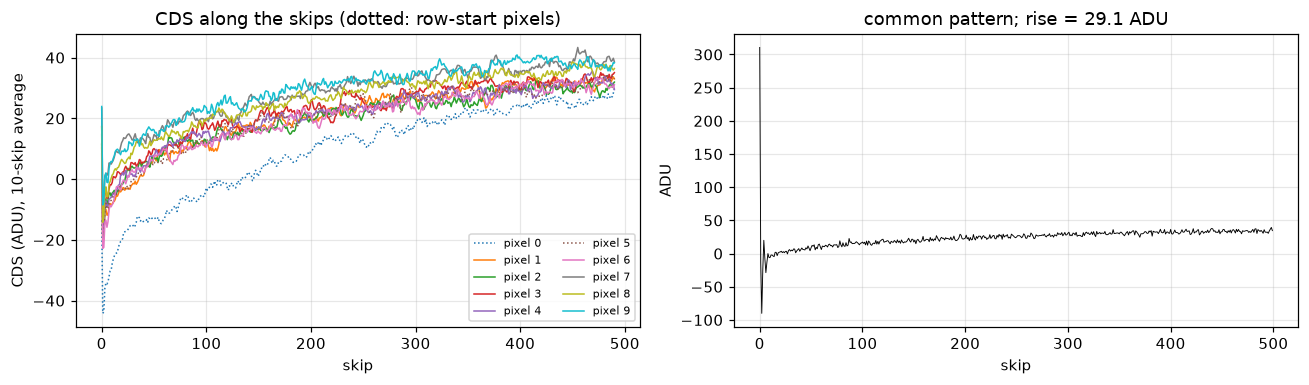

In [3]:
def common_pattern(C, pixels):
    common = np.median(C[pixels], axis=0)
    return common, common[450:].mean() - common[10:60].mean()

common, rise = common_pattern(C, GOOD)
fig, ax = plt.subplots(1, 2, figsize=(12, 3.6))
for p in range(regions.n_pixels):
    ax[0].plot(np.convolve(C[p], np.ones(10) / 10, "valid"), "-" if p in GOOD else ":", lw=1, label=f"pixel {p}")
ax[0].set(xlabel="skip", ylabel="CDS (ADU), 10-skip average", title="CDS along the skips (dotted: row-start pixels)")
ax[0].legend(ncol=2, fontsize=7)
ax[1].plot(common, lw=0.6, color="k")
ax[1].set(xlabel="skip", ylabel="ADU", title=f"common pattern; rise = {rise:.1f} ADU")
plt.tight_layout(); plt.show()

## A2. Pixel-to-pixel spread of the CDS level

**Feature:** each pixel's mean CDS minus the common pattern, giving one relative level per pixel.
From these, per trace: the spread (robust: 1.4826 × median absolute deviation, so one charged pixel
does not dominate it) and the maximum over the usable pixels. The
uncertainty uses 10-skip block means, because consecutive skips are correlated.

**Why a model might use it:** differences between pixels are mostly charge collected by the 400 CCD
pixels behind each trace pixel, plus each pixel's own offset. More dark current or spurious charge
should widen the spread. This is a **λ-related candidate**, without needing to know the gain.

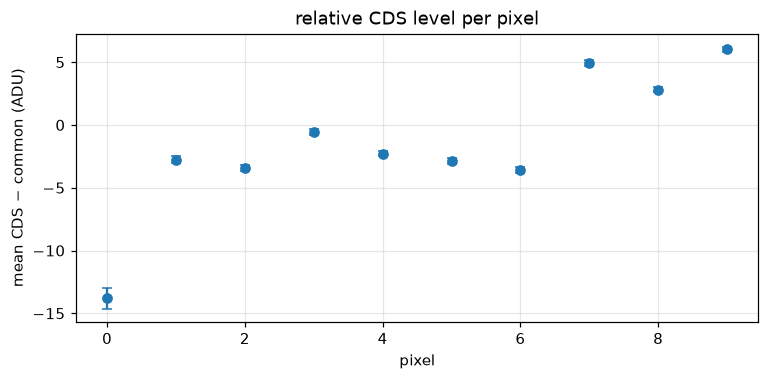

usable pixels: spread 3.06 ADU, max 6.04 ADU, typical uncertainty ±0.23 ADU


In [4]:
def relative_levels(C, pixels, first_skip=10, block=10):
    common = np.median(C[pixels], axis=0)
    out = {}
    for p in range(len(C)):
        d = C[p, first_skip:] - common[first_skip:]
        n = len(d) // block * block
        blocks = d[:n].reshape(-1, block).mean(axis=1)
        out[p] = (d.mean(), blocks.std(ddof=1) / np.sqrt(len(blocks)))
    return out

rel = relative_levels(C, GOOD)
fig, ax = plt.subplots(figsize=(8, 3.4))
ps = np.arange(regions.n_pixels)
ax.errorbar(ps, [rel[p][0] for p in ps], [rel[p][1] for p in ps], fmt="o", capsize=3)
ax.set(xlabel="pixel", ylabel="mean CDS − common (ADU)", title="relative CDS level per pixel"); plt.show()
levels = np.array([rel[p][0] for p in GOOD])
def robust_spread(x):
    return 1.4826 * np.median(np.abs(x - np.median(x)))
print(f"usable pixels: spread {robust_spread(levels):.2f} ADU, max {levels.max():.2f} ADU, "
      f"typical uncertainty ±{np.median([rel[p][1] for p in GOOD]):.2f} ADU")

Removing the common pattern makes each pixel's level precise to about ±0.2 ADU. Without it the
precision would be about ±1.3 ADU, because the pattern drifts by ~30 ADU along the skips. The spread
of a few ADU is therefore real, not measurement noise.

## A3. Charge loss along the skips of a charged pixel

**Feature:** for a pixel holding a lot of charge, the slope of its CDS along the skips relative to its
level (percent over the pixel), and the skewness of its CDS values.

**Why a model might use it:** a skipper pixel should give the same value on every skip. A steady
decrease means charge is lost or changed between measurements, at the summing-well/output-gate
transfer. That depends on `SW_*`, `OG_*` and their delays, which also affect the image.

**Availability:** only when a trace happens to contain a charged pixel. One of the five ch0 repeats
has one. For a model it is a feature with missing values, or a reason to add a controlled charge to
the trace.

trace_2x5x500_20x20_ch0_101_20261008_185459_24.RJ45ADCDATA0: pixel 0: level 18389 ADU, slope -1.062 ADU/skip = -2.83 % over the pixel, skewness +1.17


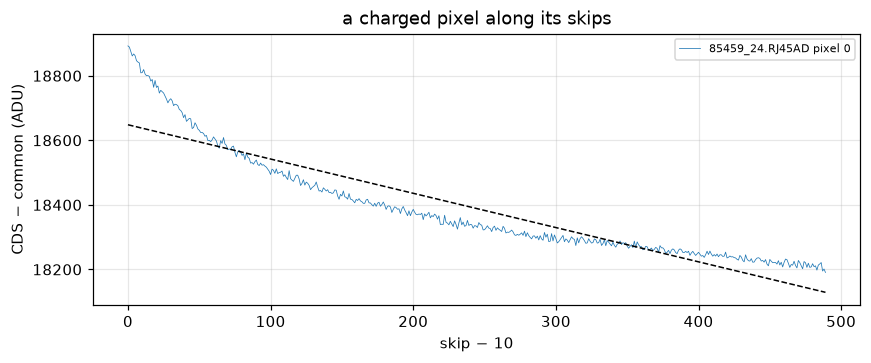

In [5]:
def charge_loss(path, min_level=1000):
    t = decode_trace(path)
    if t.quality_problems():
        return []                                     # the damaged repeat
    r = split_regions(t)
    Cm = np.array([r.cds[p] for p in range(r.n_pixels)], float)
    common = np.median(Cm[usable_pixels(r)], axis=0)
    out = []
    for p in range(r.n_pixels):
        d = Cm[p, 10:] - common[10:]
        if d.mean() > min_level:
            slope, intercept = np.polyfit(np.arange(len(d)), d, 1)
            out.append((p, d, slope, intercept))
    return out

found = [(path, item) for path in traces_of(0) for item in charge_loss(path)]
fig, ax = plt.subplots(figsize=(9, 3.2))
for path, (p, d, slope, intercept) in found:
    ax.plot(d, lw=0.5, label=f"{path.name[38:53]} pixel {p}")
    ax.plot(np.polyval([slope, intercept], np.arange(len(d))), "k--", lw=1)
    skew = ((d - d.mean())**3).mean() / d.std()**3
    print(f"{path.name}: pixel {p}: level {d.mean():.0f} ADU, slope {slope:+.3f} ADU/skip "
          f"= {slope * len(d) / d.mean() * 100:+.2f} % over the pixel, skewness {skew:+.2f}")
ax.set(xlabel="skip − 10", ylabel="CDS − common (ADU)", title="a charged pixel along its skips"); ax.legend(fontsize=7); plt.show()

In this pixel the CDS falls by a few percent over the skips and the distribution is skewed. Whether
that is charge loss or a level-dependent response of the amplifier does not matter for the model: it
is a measurable property of how a charged pixel is read, and it may change with the operating point.

---
# B. Noise character

The CDS noise after averaging many skips sets σe in the image. These features describe the
**character** of the trace's noise, which can differ even when the per-skip rms is the same.

## B1. Skip-to-skip autocorrelation of the CDS

**Feature:** the autocorrelation of the detrended CDS at lags 1–50 (a curve), or its first few values.

**Why a model might use it:** the noise of an N-skip average depends on how consecutive skips are
correlated, not only on the per-skip rms. Anticorrelated skips average down faster than 1/√N, and
correlated ones slower. Periodic pickup gives a periodic pattern.

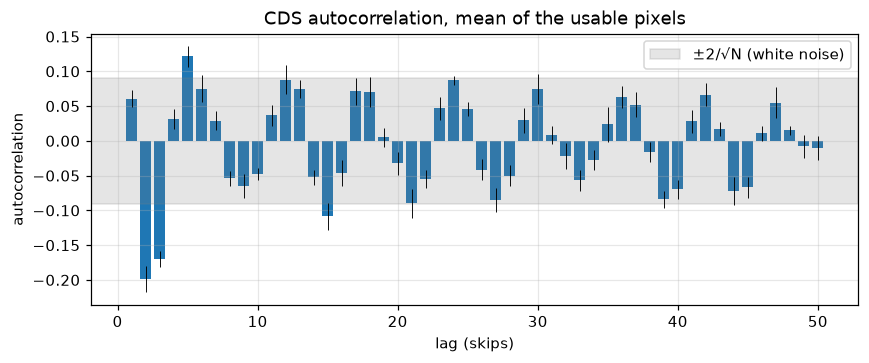

lags 1-6: [ 0.061 -0.199 -0.17   0.031  0.121  0.075]


In [6]:
def acf(x, max_lag=50):
    x = x - x.mean()
    return np.array([np.dot(x[:-k], x[k:]) / np.dot(x, x) for k in range(1, max_lag + 1)])

A = np.array([acf(detrend(C[p, 10:])) for p in GOOD])
fig, ax = plt.subplots(figsize=(9, 3.2))
lags = np.arange(1, 51)
ax.bar(lags, A.mean(0)); ax.errorbar(lags, A.mean(0), A.std(0) / np.sqrt(len(GOOD)), fmt="none", ecolor="k", lw=0.6)
band = 2 / np.sqrt(C.shape[1] - 10); ax.axhspan(-band, band, color="gray", alpha=0.2, label="±2/√N (white noise)")
ax.set(xlabel="lag (skips)", ylabel="autocorrelation", title="CDS autocorrelation, mean of the usable pixels"); ax.legend(); plt.show()
print("lags 1-6:", np.round(A.mean(0)[:6], 3))

## B2. Allan deviation

**Feature:** σ_A(n), the scatter between consecutive n-skip averages, for n = 1 to ~160 (a curve),
computed on the detrended CDS. Single numbers: σ_A at n = 50, or the slope of the curve. (On the raw
CDS, the ~30 ADU common rise of A1 makes the curve climb at large n: that is the drift, not the
noise.)

**Why a model might use it:** this is the trace's own version of "noise after averaging n skips",
the quantity that becomes σe in a skipper image. White noise falls as n^(−1/2), 1/f noise flattens,
and anticorrelated noise falls faster.

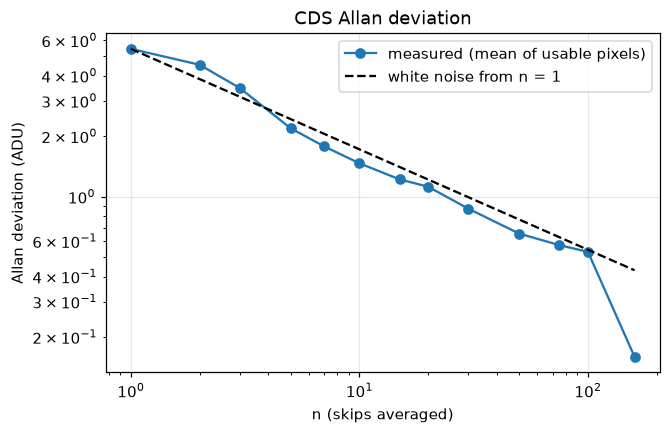

{1: 5.44, 10: 1.466, 50: 0.655, 100: 0.531}


In [7]:
def allan_deviation(x, ns):
    out = []
    for n in ns:
        m = len(x) // n
        means = x[:m * n].reshape(m, n).mean(axis=1)
        out.append(np.sqrt(0.5 * np.mean(np.diff(means) ** 2)) if m > 2 else np.nan)
    return np.array(out)

ns = np.array([1, 2, 3, 5, 7, 10, 15, 20, 30, 50, 75, 100, 160])
AD = np.array([allan_deviation(detrend(C[p, 10:]), ns) for p in GOOD])
fig, ax = plt.subplots(figsize=(6.5, 4))
ax.loglog(ns, AD.mean(0), "o-", label="measured (mean of usable pixels)")
ax.loglog(ns, AD.mean(0)[0] / np.sqrt(ns), "k--", label="white noise from n = 1")
ax.set(xlabel="n (skips averaged)", ylabel="Allan deviation (ADU)", title="CDS Allan deviation"); ax.legend(); plt.show()
print({int(n): round(float(v), 3) for n, v in zip(ns, AD.mean(0)) if n in (1, 10, 50, 100)})

## B3. Spectrum of the CDS sequence (0 – 15 kHz)

**Feature:** the power spectrum of the detrended CDS sequence, sampled at the skip rate (~30.7 kHz).
As numbers: band powers, e.g. the ratio of power below 1 kHz to power above 10 kHz.

**Why a model might use it:** the noise frequencies that survive the CDS are what limit averaging.
1/f noise rises at low frequency; anticorrelation (B1) rises towards high frequency; pickup makes
peaks.

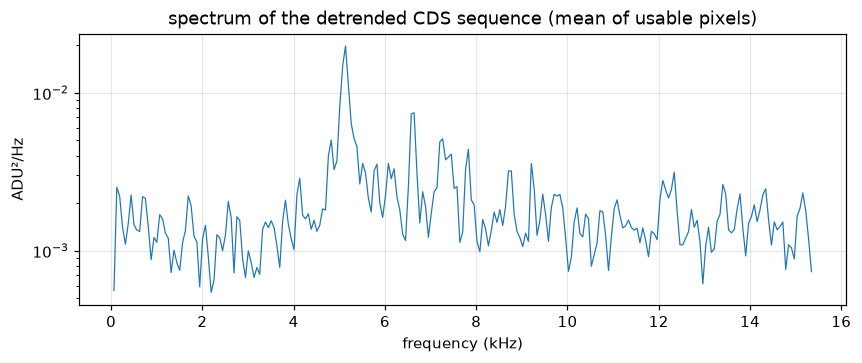

power ratio below 1 kHz / above 10 kHz: 1.05


In [8]:
def cds_spectrum(series_list, rate):
    n = min(len(s) for s in series_list)
    S = np.mean([np.abs(np.fft.rfft(s[:n] * np.hanning(n))) ** 2 for s in series_list], axis=0)
    S *= 2 / (rate * (np.hanning(n) ** 2).sum())              # one-sided density, ADU²/Hz
    return np.fft.rfftfreq(n, 1 / rate), S

f_cds, S_cds = cds_spectrum([detrend(C[p, 10:]) for p in GOOD], SKIP_RATE)
fig, ax = plt.subplots(figsize=(9, 3.2))
ax.semilogy(f_cds[1:] / 1e3, S_cds[1:], lw=0.8)
ax.set(xlabel="frequency (kHz)", ylabel="ADU²/Hz", title="spectrum of the detrended CDS sequence (mean of usable pixels)"); plt.show()
print(f"power ratio below 1 kHz / above 10 kHz: {S_cds[(f_cds > 0) & (f_cds < 1e3)].mean() / S_cds[f_cds > 10e3].mean():.2f}")

## B4. Reset-level scatter and the noise inside a cycle

**Features:**

* **reset-level scatter**: the standard deviation, from skip to skip, of each cycle's mean level
  (after removing the slow droop). Every reset sets the output node to a new random level; the CDS
  cancels that level because it subtracts two windows from the same cycle;
* **within-cycle band powers**: from the pedestal-window start to the signal-window end there is no
  reset. Removing each cycle's own mean leaves the noise *inside* the cycle; its spectrum is
  summarised as power in 0.1–0.3, 0.3–1, 1–3 and 3–7.5 MHz.

**Why a model might use it:** the reset scatter depends on the sense-node capacitance and the reset
gate (kTC noise), and the sense-node capacitance also sets the gain. The within-cycle bands are the
noise that the CDS does **not** cancel. Which band dominates tells which part of the readout chain
sets σe.

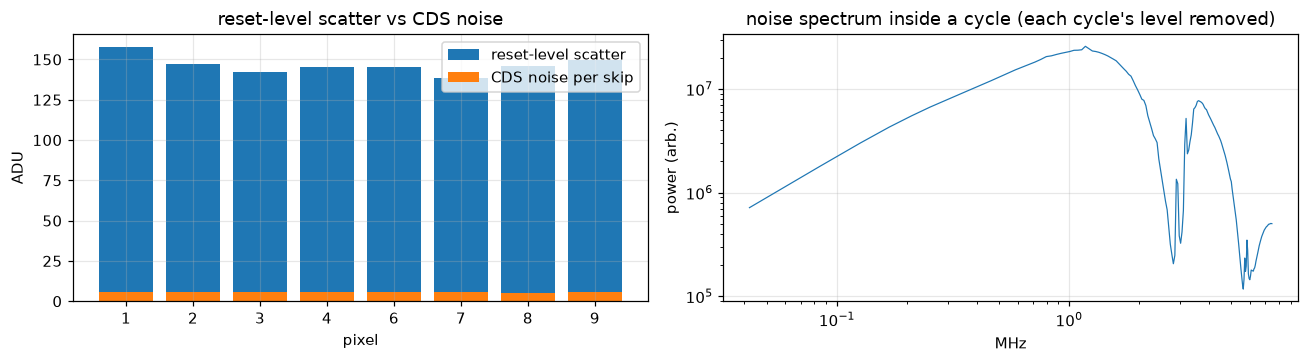

reset-level scatter 147 ADU, CDS noise 5.6 ADU
fraction of within-cycle power in 0.1-0.3 / 0.3-1 / 1-3 / 3-7.5 MHz: [0.026 0.254 0.509 0.211]


In [9]:
SEGMENT = SIG + N_PED          # pedestal-window start .. signal-window end: no reset inside

def reset_and_bands(p, bands=((0.1e6, 0.3e6), (0.3e6, 1e6), (1e6, 3e6), (3e6, 7.5e6))):
    R = residual_cycles(p)[:, :SEGMENT]
    reset_scatter = R[:, :N_PED].mean(1).std()            # each cycle's level, from skip to skip
    inside = R - R.mean(1, keepdims=True)                 # remove each cycle's own level
    S = np.mean(np.abs(np.fft.rfft(inside * np.hanning(SEGMENT), axis=1)) ** 2, axis=0)
    f = np.fft.rfftfreq(SEGMENT, 1 / SAMPLE_RATE_HZ)
    return reset_scatter, f, S, [S[(f >= a) & (f < b)].sum() / S[f >= bands[0][0]].sum() for a, b in bands]

out = [reset_and_bands(p) for p in GOOD]
f_in = out[0][1]; S_in = np.mean([o[2] for o in out], axis=0)
fig, ax = plt.subplots(1, 2, figsize=(12, 3.4))
ax[0].bar([str(p) for p in GOOD], [o[0] for o in out], label="reset-level scatter")
ax[0].bar([str(p) for p in GOOD], [detrend(C[p, 10:]).std() for p in GOOD], label="CDS noise per skip")
ax[0].set(xlabel="pixel", ylabel="ADU", title="reset-level scatter vs CDS noise"); ax[0].legend()
ax[1].loglog(f_in[1:] / 1e6, S_in[1:], lw=0.8)
ax[1].set(xlabel="MHz", ylabel="power (arb.)", title="noise spectrum inside a cycle (each cycle's level removed)")
plt.tight_layout(); plt.show()
print(f"reset-level scatter {np.mean([o[0] for o in out]):.0f} ADU, CDS noise {np.mean([detrend(C[p, 10:]).std() for p in GOOD]):.1f} ADU")
print("fraction of within-cycle power in 0.1-0.3 / 0.3-1 / 1-3 / 3-7.5 MHz:", np.round(np.mean([o[3] for o in out], axis=0), 3))

The level set by each reset scatters by over a hundred ADU from skip to skip, while the CDS noise is
a few ADU: the CDS removes about 97 % of it. The size of that scatter and the shape of the
within-cycle spectrum are both candidate inputs.

## B5. Noise against window length (offline re-integration)

**Feature:** the CDS recomputed from the raw samples with shorter windows inside the real ones, and
its noise as a function of the window length L (a curve). Single number: σ(L = 75) / σ(L = 150).
For white noise this ratio would be √2 = 1.41.

**Why a model might use it:** it describes how the noise behaves within the 10 µs integration, which
is what `delayInt` and the window placement act on. A later start (window ending at the same place)
also shows whether the start of the window is still settling.

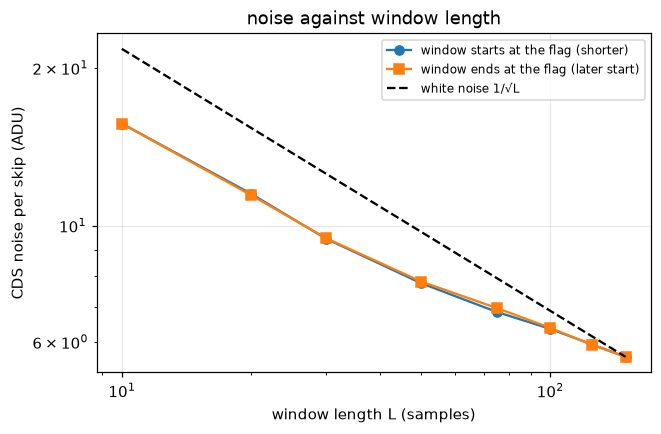

sigma(75)/sigma(150) = 1.218 (white noise: 1.414)


In [10]:
def reintegrated_noise(p, length, offset):
    Y = cycles(p)
    c = Y[:, offset:offset + length].mean(1) - Y[:, SIG + offset:SIG + offset + length].mean(1)
    return detrend(c[10:]).std()

lengths = [10, 20, 30, 50, 75, 100, 125, 150]
early = np.array([[reintegrated_noise(p, L, 0) for L in lengths] for p in GOOD]).mean(0)
late = np.array([[reintegrated_noise(p, L, N_PED - L) for L in lengths] for p in GOOD]).mean(0)
fig, ax = plt.subplots(figsize=(6.5, 4))
ax.loglog(lengths, early, "o-", label="window starts at the flag (shorter)")
ax.loglog(lengths, late, "s-", label="window ends at the flag (later start)")
ax.loglog(lengths, early[-1] * np.sqrt(150 / np.array(lengths)), "k--", label="white noise 1/√L")
ax.set(xlabel="window length L (samples)", ylabel="CDS noise per skip (ADU)", title="noise against window length"); ax.legend(fontsize=8); plt.show()
print(f"sigma(75)/sigma(150) = {early[4] / early[-1]:.3f} (white noise: 1.414)")

## B6. Settling inside the windows

**Feature:** the average shape of the waveform inside the pedestal and the signal window, and its
change across each window (ADU).

**Why a model might use it:** a window that is not flat means the signal is still moving while it is
integrated. Then timing jitter and small level changes leak into the CDS. How flat the windows are
depends directly on the clock delays (`delaySW*`, `delayRG*`, `delayOG*`) and on the amplifier's
speed.

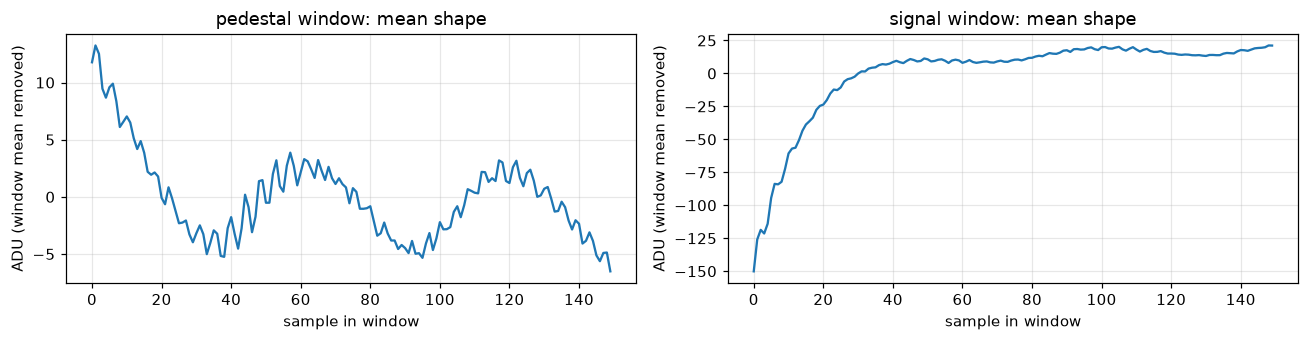

{'pedestal': '-14.0 ADU from start to end', 'signal': '+123.7 ADU from start to end'}


In [11]:
fig, ax = plt.subplots(1, 2, figsize=(12, 3.2))
settling = {}
for name, start, axis in (("pedestal", 0, ax[0]), ("signal", SIG, ax[1])):
    shapes = []
    for p in GOOD:
        win = cycles(p)[10:, start:start + N_PED]
        shapes.append((win - win.mean(1, keepdims=True)).mean(0))
    m = np.mean(shapes, 0); axis.plot(m)
    settling[name] = m[-10:].mean() - m[:10].mean()
    axis.set(xlabel="sample in window", ylabel="ADU (window mean removed)", title=f"{name} window: mean shape")
plt.tight_layout(); plt.show()
print({k: f"{v:+.1f} ADU from start to end" for k, v in settling.items()})

In this trace the **signal window is still settling**: it starts about 150 ADU below its final level
and needs about 30 samples (2 µs) to settle, after the summing-well clock moved the charge. The
pedestal window is nearly flat, with a slow ripple of a few ADU. Shorter or later windows (B5) and
the summing-well delays act exactly on this.

## B7. Baseline coupling and noise along the skips

**Features:**

* the slope of the CDS against the skip's baseline level, over the skips of a pixel (the baseline
  droops by thousands of ADU);
* the CDS noise in 50-skip blocks along the pixel (a curve).

**Why a model might use it:** an ideal CDS ignores the baseline. The slope measures how much leaks
through (it produces the common pattern of A1), a common-mode-rejection property of the output
stage. The output-stage biases (VDD, VDRAIN, VR) are among the parameters to optimise. Noise that
changes along the skips means the noise depends on the operating point of the amplifier.

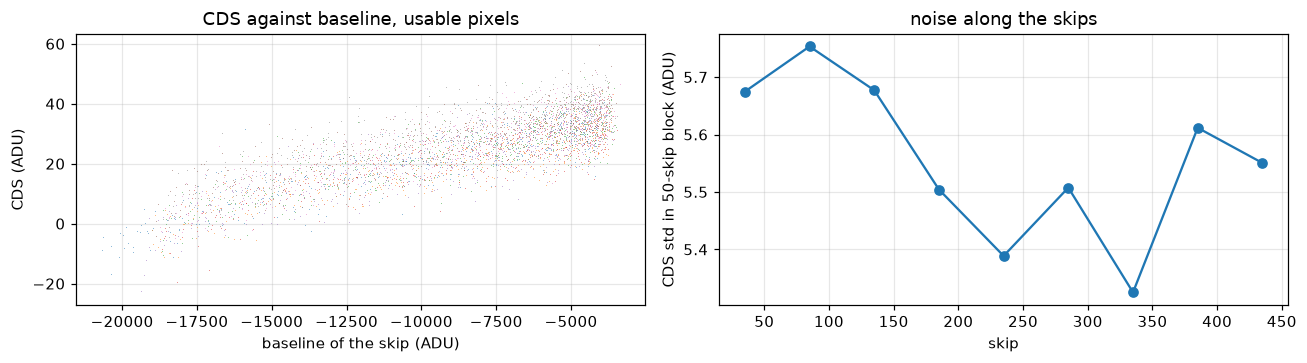

coupling dCDS/dbaseline = 0.00211 ± 0.00007 (pixel scatter)


In [12]:
def baseline_coupling(p, first_skip=10):
    base = cycles(p)[first_skip:, :N_PED].mean(1)
    return np.polyfit(base, C[p, first_skip:], 1)[0], base

fig, ax = plt.subplots(1, 2, figsize=(12, 3.4))
coupling = []
for p in GOOD:
    s, base = baseline_coupling(p); coupling.append(s)
    ax[0].plot(base, C[p, 10:], ",", alpha=0.5)
ax[0].set(xlabel="baseline of the skip (ADU)", ylabel="CDS (ADU)", title="CDS against baseline, usable pixels")
block_noise = np.array([[detrend(C[p, 10:])[i:i + 50].std() for i in range(0, 450, 50)] for p in GOOD])
ax[1].plot(np.arange(10, 460, 50) + 25, block_noise.mean(0), "o-")
ax[1].set(xlabel="skip", ylabel="CDS std in 50-skip block (ADU)", title="noise along the skips")
plt.tight_layout(); plt.show()
print(f"coupling dCDS/dbaseline = {np.mean(coupling):.5f} ± {np.std(coupling):.5f} (pixel scatter)")

---
# C. Discrete and transient noise

## C1. Steps (random telegraph noise)

**Feature:** the largest step in the per-skip baseline and in the CDS: the difference between the
20-skip means before and after a skip, in units of its noise. The same statistic on shuffled series
(where steps cannot exist) shows the chance level.

**Why a model might use it:** traps in the output transistor make the level jump between discrete
values (telegraph noise). This is a known skipper noise source that a plain rms hides. It can change
with the transistor's bias.

baseline: largest step t = 2.3; shuffled series: 95 % below 4.1


CDS: largest step t = 3.2; shuffled series: 95 % below 4.2


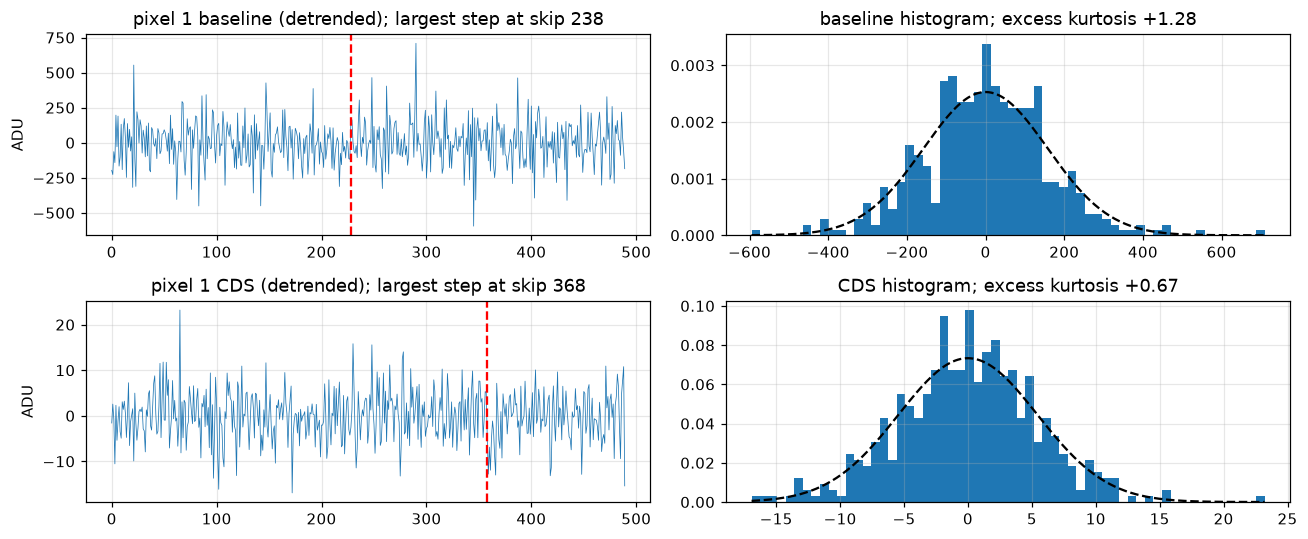

In [13]:
def largest_step(x, window=20):
    t = []
    for k in range(window, len(x) - window):
        a, b = x[k - window:k], x[k:k + window]
        t.append(abs(b.mean() - a.mean()) / np.sqrt(a.var(ddof=1) / window + b.var(ddof=1) / window))
    return int(np.argmax(t)) + window, max(t)

rng = np.random.default_rng(0)
p = GOOD[0]
series = {"baseline": detrend(cycles(p)[10:, :N_PED].mean(1)), "CDS": detrend(C[p, 10:])}
fig, ax = plt.subplots(2, 2, figsize=(12, 5))
for row, (name, x) in enumerate(series.items()):
    k, tmax = largest_step(x)
    null = [largest_step(rng.permutation(x))[1] for _ in range(100)]
    ax[row, 0].plot(x, lw=0.5); ax[row, 0].axvline(k, color="r", ls="--")
    ax[row, 0].set(title=f"pixel {p} {name} (detrended); largest step at skip {k + 10}", ylabel="ADU")
    ax[row, 1].hist(x, 60, density=True)
    xs = np.linspace(x.min(), x.max(), 200); ax[row, 1].plot(xs, np.exp(-xs**2 / (2 * x.var())) / np.sqrt(2 * np.pi * x.var()), "k--")
    ax[row, 1].set(title=f"{name} histogram; excess kurtosis {((x - x.mean())**4).mean() / x.var()**2 - 3:+.2f}")
    print(f"{name}: largest step t = {tmax:.1f}; shuffled series: 95 % below {np.percentile(null, 95):.1f}")
plt.tight_layout(); plt.show()

## C2. Outliers

**Feature:** the fraction of skips whose detrended CDS is more than 5 robust σ from the median, and
the excess kurtosis.

**Why a model might use it:** glitches, bursts of pickup or charge arriving during the readout make
heavy tails. Those inflate σe in the image without changing the core of the distribution.

In [14]:
def outlier_stats(x, threshold=5):
    med = np.median(x); robust = 1.4826 * np.median(np.abs(x - med))
    return np.mean(np.abs((x - med) / robust) > threshold), ((x - x.mean())**4).mean() / x.var()**2 - 3

for p in GOOD:
    frac, kurt = outlier_stats(detrend(C[p, 10:]))
    print(f"pixel {p}: outlier fraction {frac:.4f}, excess kurtosis {kurt:+.2f}")

pixel 1: outlier fraction 0.0000, excess kurtosis +0.67
pixel 2: outlier fraction 0.0000, excess kurtosis -0.35
pixel 3: outlier fraction 0.0000, excess kurtosis +0.14
pixel 4: outlier fraction 0.0000, excess kurtosis +0.08
pixel 6: outlier fraction 0.0000, excess kurtosis +0.00
pixel 7: outlier fraction 0.0000, excess kurtosis +0.29
pixel 8: outlier fraction 0.0000, excess kurtosis +0.13
pixel 9: outlier fraction 0.0000, excess kurtosis -0.06


## C3. Interference lines

**Feature:** narrow peaks in the within-cycle spectrum (B4, 30 kHz resolution, up to 7.5 MHz) and in
the CDS spectrum (B3, 60 Hz resolution, up to 15 kHz): their frequencies and heights above the local
median.

**Why a model might use it:** pickup at a fixed frequency adds noise that averaging removes only
partly. Whether it aliases into the CDS depends on the skip period, so it can change with the timing
parameters.

lines (MHz, height): []
lines (kHz, height): []


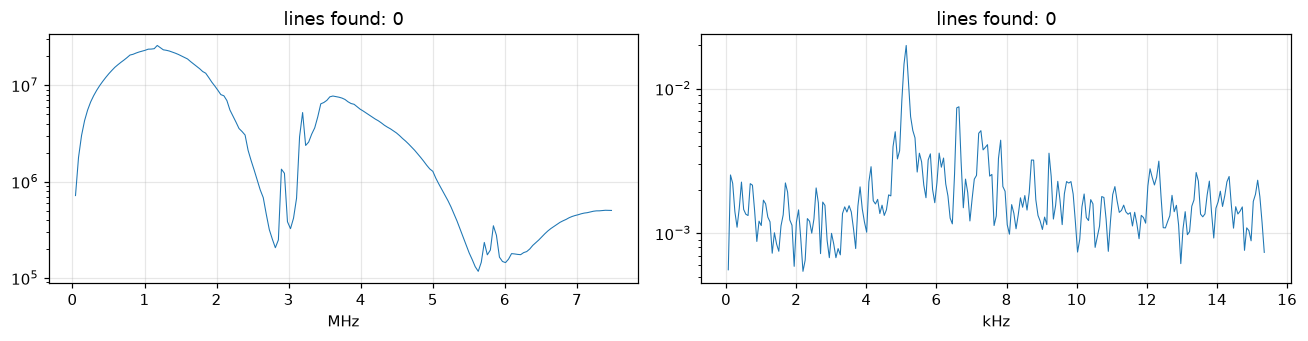

In [15]:
def find_lines(f, S, factor=5, half_width=5):
    lines = []
    for i in range(half_width, len(S) - half_width):
        local = np.median(np.r_[S[i - half_width:i], S[i + 1:i + half_width + 1]])
        if S[i] > factor * local and S[i] == S[i - 1:i + 2].max():
            lines.append((f[i], S[i] / local))
    return lines

fig, ax = plt.subplots(1, 2, figsize=(12, 3.2))
for axis, f, S, unit, scale in ((ax[0], f_in[1:], S_in[1:], "MHz", 1e6), (ax[1], f_cds[1:], S_cds[1:], "kHz", 1e3)):
    axis.semilogy(f / scale, S, lw=0.7)
    lines = find_lines(f, S)
    for fl, ratio in lines:
        axis.plot(fl / scale, S[np.argmin(abs(f - fl))], "rv")
    axis.set(xlabel=unit, title=f"lines found: {len(lines)}")
    print(f"lines ({unit}, height):", [(round(a / scale, 3), round(b, 1)) for a, b in lines][:10])
plt.tight_layout(); plt.show()

## C4. ADC code distribution

**Feature:** χ² of the low-bit histogram (value mod 64) against a flat distribution, and the fraction
of 1s in each low bit.

**Why a model might use it:** uneven ADC codes add a small noise of their own. It is a property of
the ADC channel, not of the CCD settings, so it mostly helps the model tell channels apart (and
catches a failing ADC).

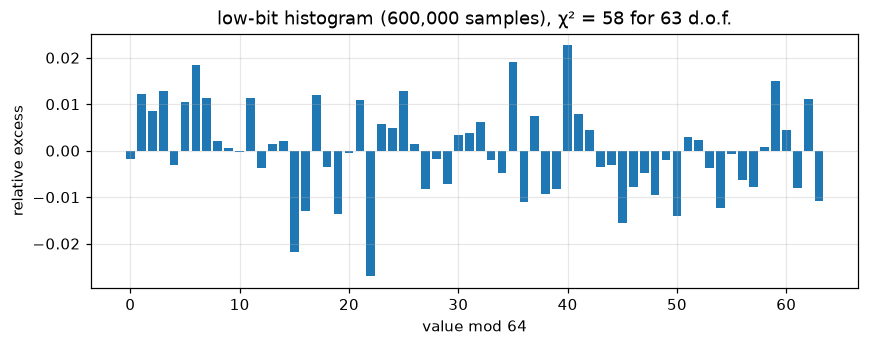

fraction of 1s per bit (0.5 = unbiased): [0.5006 0.4997 0.4989 0.5    0.4991 0.4994 0.5002 0.505 ]


In [16]:
in_windows = np.concatenate([cycles(p)[:, :N_PED].ravel() for p in GOOD]).astype(np.int64)
low = np.mod(in_windows, 64); counts = np.bincount(low, minlength=64); expected = len(low) / 64
chi2 = ((counts - expected) ** 2 / expected).sum()
fig, ax = plt.subplots(figsize=(9, 3))
ax.bar(np.arange(64), counts / expected - 1)
ax.set(xlabel="value mod 64", ylabel="relative excess", title=f"low-bit histogram ({len(low):,} samples), χ² = {chi2:.0f} for 63 d.o.f.")
plt.show()
print("fraction of 1s per bit (0.5 = unbiased):", np.round([(in_windows >> b & 1).mean() for b in range(8)], 4))

---
# D. Edges

Positions inside the cycle, from the sequencer (`reference_v5_pumping.seq`):

* pedestal window: 0–150;
* summing-well clock (`SW`): 150–207, where the **dip** is;
* signal window: 207–357;
* output gate and **reset** (`OG`, `RG`): from 357; the **pulse** peaks near sample 374;
* reset settling: until the next pedestal window.

## D1. Timing jitter

**Feature:** the time of the reset pulse's rising edge in every skip, to a fraction of a sample.
Fitted with a straight line against the skip number, the slope is the true period and the scatter
around the line is the **jitter** (ns rms).

**Why a model might use it:** where a window sits on a slope, jitter becomes noise. Jitter depends on
the clock (internal or external) and on how steep the edges are.

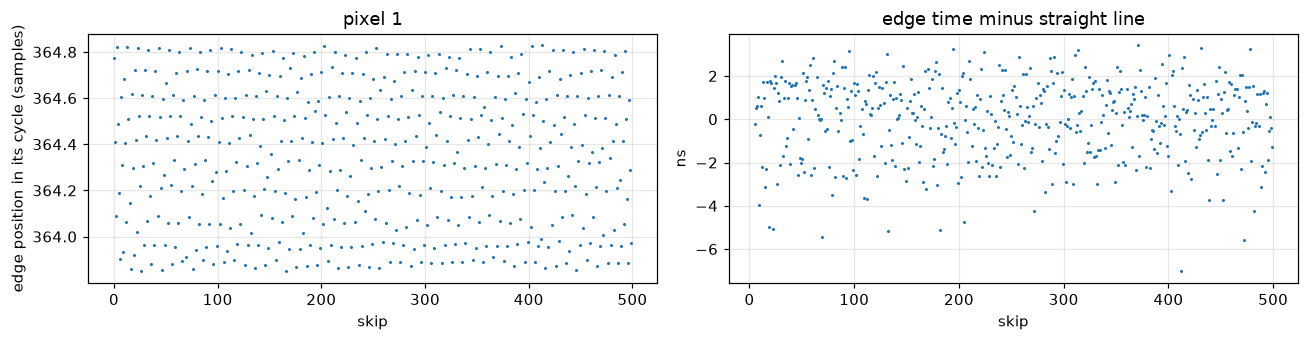

true period 488.7000 samples (sequencer: 488.7); jitter 1.74 ns rms


In [17]:
starts, _ = trace.window_slices()
breaks = np.flatnonzero(np.diff(starts) > 2 * P)
groups = list(zip(np.r_[0, breaks + 1], np.r_[breaks, len(starts) - 1]))
abs_starts = [starts[a:b] for a, b in groups]          # absolute first sample of every cycle, per pixel

def edge_times(Y, cycle_starts, lo=350, hi=420):
    out = []
    for k, y in enumerate(Y):
        seg = y[lo:hi]; before = y[340:356].mean(); i = int(np.argmax(seg)); level = (before + seg[i]) / 2
        j = np.flatnonzero(seg[:i + 1] < level)[-1]
        out.append(cycle_starts[k] + lo + j + (level - seg[j]) / (seg[j + 1] - seg[j]))
    return np.array(out)

fig, ax = plt.subplots(1, 2, figsize=(12, 3.2))
jitters, fits = [], {}
for p in GOOD:
    t = edge_times(cycles(p), abs_starts[p]); k = np.arange(len(t))
    fit = np.polyfit(k[5:], t[5:], 1); resid = t - np.polyval(fit, k)
    jitters.append(resid[5:].std()); fits[p] = fit
    if p == GOOD[0]:
        ax[0].plot(k, t - abs_starts[p], ".", ms=2); ax[0].set(xlabel="skip", ylabel="edge position in its cycle (samples)", title=f"pixel {p}")
        ax[1].plot(k[5:], resid[5:] / SAMPLE_RATE_HZ * 1e9, ".", ms=2); ax[1].set(xlabel="skip", ylabel="ns", title="edge time minus straight line")
plt.tight_layout(); plt.show()
print(f"true period {np.mean([f[0] for f in fits.values()]):.4f} samples (sequencer: 488.7); "
      f"jitter {np.mean(jitters) / SAMPLE_RATE_HZ * 1e9:.2f} ns rms")

The edge saws by a third of a sample within its cycle, because a cycle is 488.7 samples but always
starts on a whole sample (the 3.33-skip beat). Against absolute time the edges lie on a straight line
with the sequencer's period. The nanosecond-level scatter is the jitter.

## D2. The waveform at a third of a sample (equivalent-time sampling)

**Feature:** the pulse shape rebuilt from many skips at sub-sample resolution. Numbers: the 10–90 %
rise time and the peak height.

**How:** each sample is placed at its exact time relative to the fitted edge line and averaged in
0.1-sample bins. This works because the sampling phase walks by 0.3 samples every skip.

**Why a model might use it:** the rise time and shape of an edge are the bandwidth of the video chain.
Bandwidth shapes the noise spectrum and how fast the windows settle (B6).

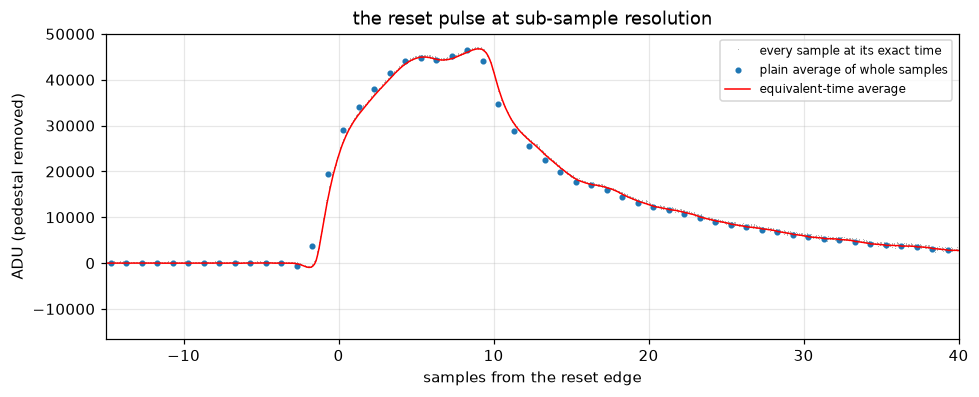

10-90 % rise time 333 ns, peak 46744 ADU


In [18]:
def equivalent_time(p, fit, first_skip=100, lo=-15, hi=60, bin_width=0.1):
    Y = cycles(p); taus, vals = [], []
    for k in range(first_skip, len(Y)):
        tau = abs_starts[p][k] + np.arange(P) - np.polyval(fit, k)
        sel = (tau > lo) & (tau < hi)
        taus.append(tau[sel]); vals.append((Y[k] - Y[k, :N_PED].mean())[sel])
    taus, vals = np.concatenate(taus), np.concatenate(vals)
    bins = np.arange(lo, hi + bin_width, bin_width); idx = np.digitize(taus, bins)
    mean = np.array([vals[idx == i].mean() if np.any(idx == i) else np.nan for i in range(1, len(bins))])
    return bins[:-1] + bin_width / 2, mean, taus, vals

p = GOOD[0]
centers, ets, taus, vals = equivalent_time(p, fits[p])
plain = cycles(p)[100:] - cycles(p)[100:, :N_PED].mean(1, keepdims=True)
edge_in_cycle = np.polyval(fits[p], 100) - abs_starts[p][100]
fig, ax = plt.subplots(figsize=(10, 3.6))
ax.plot(taus[::7], vals[::7], ",", color="0.7", label="every sample at its exact time")
ax.plot(np.arange(P) - edge_in_cycle, plain.mean(0), "o", ms=3, label="plain average of whole samples")
ax.plot(centers, ets, "r-", lw=1, label="equivalent-time average")
ax.set(xlim=(-15, 40), xlabel="samples from the reset edge", ylabel="ADU (pedestal removed)", title="the reset pulse at sub-sample resolution")
ax.legend(fontsize=8); plt.show()
good_bins = np.isfinite(ets)
rise = centers[good_bins & (ets > 0.1 * np.nanmax(ets))][0], centers[good_bins & (ets > 0.9 * np.nanmax(ets))][0]
print(f"10-90 % rise time {(rise[1] - rise[0]) / SAMPLE_RATE_HZ * 1e9:.0f} ns, peak {np.nanmax(ets):.0f} ADU")

## D3. Recovery after the pulse

**Feature:** after the peak the waveform relaxes. Model: two exponentials and a constant,
A₁e^(−t/τ₁) + A₂e^(−t/τ₂) + c. Numbers: τ₁, τ₂, A₁, A₂, and the rms of what remains. If what
remains oscillates, its main frequency and amplitude are **ringing** features.

**How:** a grid over τ₁ < τ₂, with linear least squares for the amplitudes at every grid point (the
same method as the existing fit tools).

**Why a model might use it:** the recovery time constants are the amplifier's response. A slow tail
still present in the next pedestal window shifts the CDS.

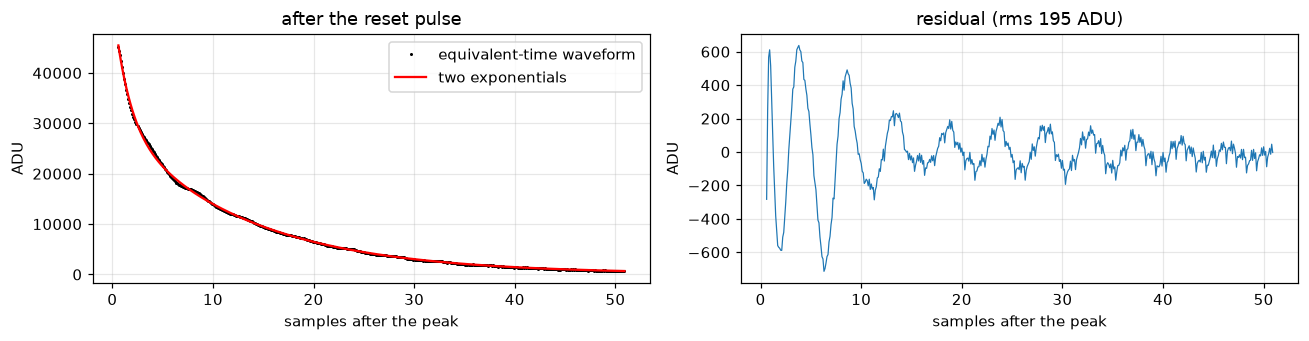

tau1 0.102 µs (A1 24645 ADU), tau2 0.859 µs (A2 30086 ADU); residual rms 195 ADU, strongest residual frequency 3.0 MHz


In [19]:
def fit_two_exponentials(t, y, tau_grid):
    best = None
    for i, t1 in enumerate(tau_grid):
        for t2 in tau_grid[i + 1:]:
            X = np.column_stack([np.exp(-t / t1), np.exp(-t / t2), np.ones_like(t)])
            coef, *_ = np.linalg.lstsq(X, y, rcond=None)
            sse = np.sum((X @ coef - y) ** 2)
            if best is None or sse < best[0]:
                best = (sse, t1, t2, coef, X @ coef)
    return best

peak_at = centers[np.nanargmax(ets)]
sel = (centers > peak_at + 0.5) & np.isfinite(ets)
t_after, y_after = centers[sel] - peak_at, ets[sel]
sse, tau1, tau2, coef, model = fit_two_exponentials(t_after, y_after, np.geomspace(0.5, 200, 60))
resid = y_after - model
spec = np.abs(np.fft.rfft(resid * np.hanning(len(resid)))); f_res = np.fft.rfftfreq(len(resid), 0.1 / SAMPLE_RATE_HZ)
f_peak = f_res[1:][np.argmax(spec[1:])]
fig, ax = plt.subplots(1, 2, figsize=(12, 3.2))
ax[0].plot(t_after, y_after, "k.", ms=2, label="equivalent-time waveform"); ax[0].plot(t_after, model, "r-", label="two exponentials")
ax[0].set(xlabel="samples after the peak", ylabel="ADU", title="after the reset pulse"); ax[0].legend()
ax[1].plot(t_after, resid, lw=0.8); ax[1].set(xlabel="samples after the peak", ylabel="ADU", title=f"residual (rms {resid.std():.0f} ADU)")
plt.tight_layout(); plt.show()
print(f"tau1 {tau1 / 15:.3f} µs (A1 {coef[0]:.0f} ADU), tau2 {tau2 / 15:.3f} µs (A2 {coef[1]:.0f} ADU); "
      f"residual rms {resid.std():.0f} ADU, strongest residual frequency {f_peak / 1e6:.1f} MHz")

In this trace the two exponentials leave a clear **decaying oscillation at about 3 MHz** (period
about 5 samples), which dies out within about 15 samples (1 µs): the video chain rings after the
reset pulse. Its frequency, amplitude and decay are three more features.

## D4. Feedthrough per volt

**Feature:** the dip (summing-well clock) and the reset pulse are clock signals coupled onto the
output node and amplified by the same chain as the charge signal. Their heights divided by the clock
swings (`SW_1_H − SW_1_L`, `RG_1_H − RG_1_L`, from θ) give couplings in ADU/V, and their ratio
cancels the common amplification.

**Why a model might use it:** the per-volt values may scale with the conversion gain, which the
model can test against the WADERs gain. If the ratio stays put while the per-volt values move, the
change was in the common amplification.

Assumption: channel 0 uses `SW_1`/`RG_1`. The channel-to-amplifier wiring is in the bcf
(`ch0 = CCD_A`) and should be confirmed.

In [20]:
def feedthrough(Y, n_ped=N_PED, sig=SIG):
    shape = (Y[10:] - Y[10:, :n_ped].mean(1, keepdims=True)).mean(0)
    dip = shape[n_ped:sig].min()
    pulse = shape[sig + n_ped:].max() - shape[sig + n_ped - 20:sig + n_ped].mean()
    return dip, pulse

sw_swing = meta["SW_1_H"] - meta["SW_1_L"]; rg_swing = meta["RG_1_H"] - meta["RG_1_L"]
values = np.array([feedthrough(cycles(p)) for p in GOOD])
print(f"SW swing {sw_swing} V, RG swing {rg_swing} V")
print(f"dip   {values[:, 0].mean():8.0f} ADU -> {values[:, 0].mean() / sw_swing:7.0f} ADU/V  (pixel scatter {values[:, 0].std():.0f})")
print(f"pulse {values[:, 1].mean():8.0f} ADU -> {values[:, 1].mean() / rg_swing:7.0f} ADU/V  (pixel scatter {values[:, 1].std():.0f})")
print(f"ratio pulse/dip {values[:, 1].mean() / values[:, 0].mean():.3f}")

SW swing 7.0 V, RG swing 6.0 V
dip     -13449 ADU ->   -1921 ADU/V  (pixel scatter 4)
pulse    46530 ADU ->    7755 ADU/V  (pixel scatter 31)
ratio pulse/dip -3.460


## D5. Variation along the cycle

**Feature:** the standard deviation across skips at every position of the cycle, after subtracting
each skip's own pedestal level (a curve of 489 points). It shows where in the cycle the waveform
varies from skip to skip.

**Why a model might use it:** the values inside the windows are the noise that enters the CDS. The
values at the edges show how strongly timing moves the waveform. A model can use the whole curve or a
few points (window level, edge peaks, the level after the reset).

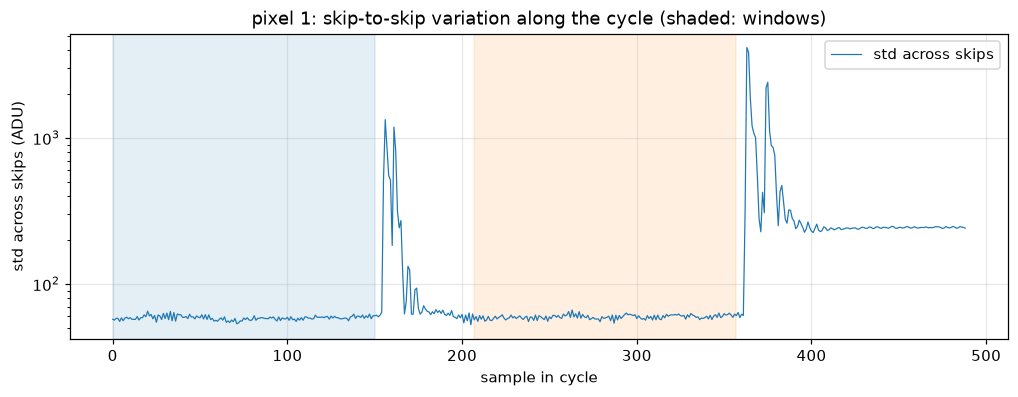

median in the signal window 59.6 ADU; peak at the dip 1334 ADU; peak at the reset pulse 4153 ADU; after the reset 243 ADU


In [21]:
Yp = cycles(GOOD[0])[10:]; Yp = Yp - Yp[:, :N_PED].mean(1, keepdims=True)
profile = Yp.std(0)
fig, ax = plt.subplots(figsize=(11, 3.6))
ax.semilogy(profile, lw=0.8, label="std across skips")
for a, b, c in ((0, N_PED, "tab:blue"), (SIG, SIG + N_PED, "tab:orange")):
    ax.axvspan(a, b, color=c, alpha=0.12)
ax.set(xlabel="sample in cycle", ylabel="std across skips (ADU)", title=f"pixel {GOOD[0]}: skip-to-skip variation along the cycle (shaded: windows)")
ax.legend(); plt.show()
print(f"median in the signal window {np.median(profile[SIG:SIG + N_PED]):.1f} ADU; peak at the dip {profile[N_PED:SIG].max():.0f} ADU; "
      f"peak at the reset pulse {profile[360:390].max():.0f} ADU; after the reset {np.median(profile[420:]):.0f} ADU")

---
# E. Slow structure

The variation is small and flat inside both windows. It is large at the two edges (the dip and the
reset pulse), where the waveform is steep, so a tiny shift in time is a big change in level. E4 shows
that this edge variation is mostly the sub-sample phase walk. After the reset the level varies by
a few hundred ADU from skip to skip: that is the reset-level scatter of B4, still present because
each skip's pedestal is subtracted only from its *own* cycle.

## E1. Row-start recovery

**Feature:** pixels 0 and 5 start a row, right after 20 vertical transfers, and their baseline starts
far lower. The difference between a row-start pixel and the next pixel, skip by skip, is fitted with
an exponential: its amplitude and time constant.

**Why a model might use it:** this is the electronics recovering from the parallel clocking. It
should respond to the vertical clock levels and timing (`V*`, `delay_V*`), which are scan parameters.

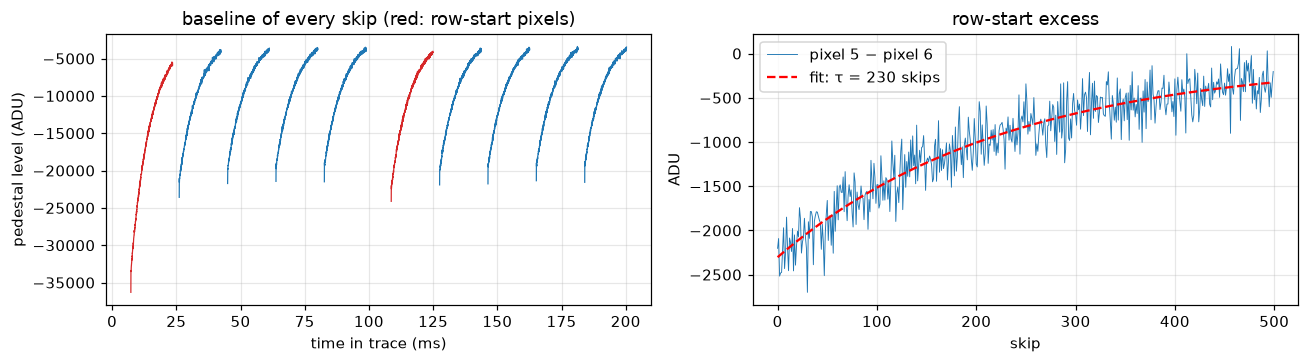

row-start recovery: amplitude -2233 ADU, time constant 230 skips = 7.5 ms


In [22]:
fig, ax = plt.subplots(1, 2, figsize=(12, 3.4))
for p in range(regions.n_pixels):
    t_ms = np.asarray(abs_starts[p], float) / SAMPLE_RATE_HZ * 1e3
    ax[0].plot(t_ms, cycles(p)[:, :N_PED].mean(1), lw=0.8, color="tab:red" if p in row_start_pixels(regions) else "tab:blue")
ax[0].set(xlabel="time in trace (ms)", ylabel="pedestal level (ADU)", title="baseline of every skip (red: row-start pixels)")
rs = row_start_pixels(regions)[1]
diff = cycles(rs)[:, :N_PED].mean(1) - cycles(rs + 1)[:, :N_PED].mean(1)
k = np.arange(len(diff), dtype=float)
tau, amp, off = fit_exponential(k, diff, 2, 2000)
ax[1].plot(diff, lw=0.6, label=f"pixel {rs} − pixel {rs + 1}")
ax[1].plot(amp * np.exp(-k / tau) + off, "r--", label=f"fit: τ = {tau:.0f} skips")
ax[1].set(xlabel="skip", ylabel="ADU", title="row-start excess"); ax[1].legend()
plt.tight_layout(); plt.show()
print(f"row-start recovery: amplitude {amp:.0f} ADU, time constant {tau:.0f} skips = {tau / SKIP_RATE * 1e3:.1f} ms")

## E2. Drift across the trace

**Feature:** the baseline at the same skip number (skip 250) in successive usable pixels, against
time: its slope in ADU/ms.

**Why a model might use it:** slow drift over the 200 ms of the trace (thermal, supplies) is
separate from the droop inside each pixel. It adds low-frequency noise to long images.

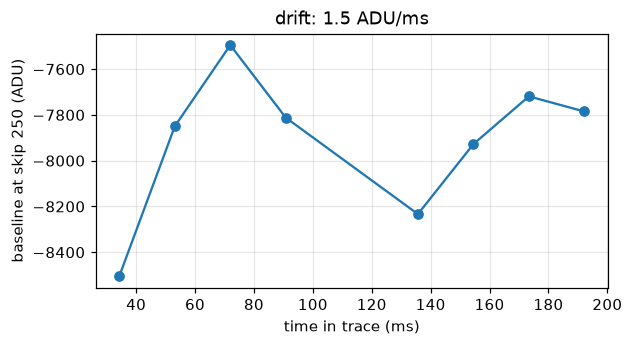

In [23]:
mid = np.array([[abs_starts[p][250] / SAMPLE_RATE_HZ * 1e3, cycles(p)[250, :N_PED].mean()] for p in GOOD])
slope = np.polyfit(mid[:, 0], mid[:, 1], 1)[0]
fig, ax = plt.subplots(figsize=(6, 3)); ax.plot(mid[:, 0], mid[:, 1], "o-")
ax.set(xlabel="time in trace (ms)", ylabel="baseline at skip 250 (ADU)", title=f"drift: {slope:.1f} ADU/ms"); plt.show()

With only two rows of 4 usable pixels, row-to-row differences and drift are mixed together. More
pixels per row would separate them.

## E3. Horizontal transfers

**Feature:** the peak-to-peak amplitude of each of the 19 complete horizontal transfers before a
pixel, its trend from the first to the last transfer, and the scatter between transfers.

**Why a model might use it:** these waveforms are the H-clock feedthrough. Their amplitude should
follow the `H*` rails, and differences between transfers can come from charge moving in the serial
register.

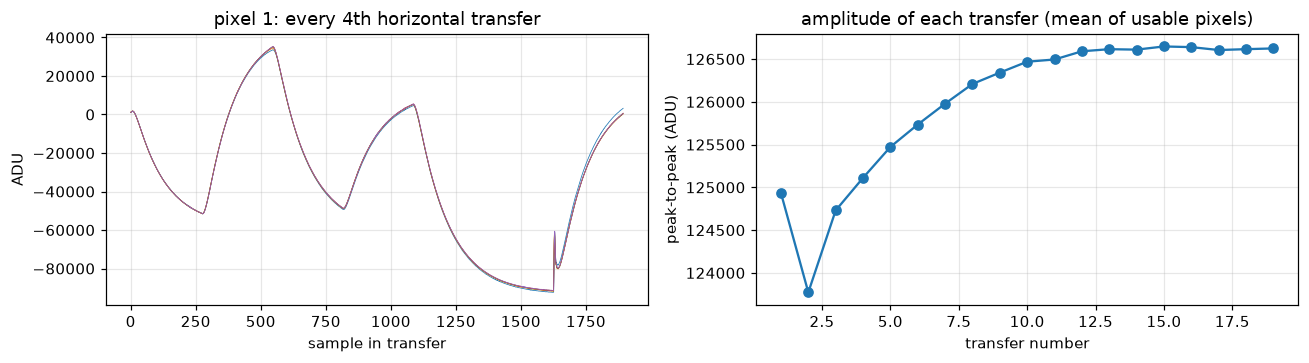

peak-to-peak 126010 ADU; first -> last transfer 124934 -> 126624; scatter between transfers 817 ADU


In [24]:
fig, ax = plt.subplots(1, 2, figsize=(12, 3.4))
amps = []
for p in GOOD:
    H = regions.h[p].astype(float); H = H - H[:, :30].mean(1, keepdims=True)
    amps.append(H.max(1) - H.min(1))
    if p == GOOD[0]:
        ax[0].plot(H.T[:, ::4], lw=0.5); ax[0].set(xlabel="sample in transfer", ylabel="ADU", title=f"pixel {p}: every 4th horizontal transfer")
amps = np.array(amps)
ax[1].plot(np.arange(1, amps.shape[1] + 1), amps.mean(0), "o-")
ax[1].set(xlabel="transfer number", ylabel="peak-to-peak (ADU)", title="amplitude of each transfer (mean of usable pixels)")
plt.tight_layout(); plt.show()
print(f"peak-to-peak {amps.mean():.0f} ADU; first -> last transfer {amps[:, 0].mean():.0f} -> {amps[:, -1].mean():.0f}; "
      f"scatter between transfers {amps.std(1).mean():.0f} ADU")

## E4. Principal components of the skip-to-skip variation

**Feature:** a singular value decomposition of `residual_cycles` (all skip-to-skip variation) finds
the few **shapes** that make up most of it. Numbers: the fraction of variance in the first
components. Curves: the component shapes and their per-skip scores.

**Why a model might use it:** this is the simplest form of learning features from the data. A
component shaped like the waveform's derivative is timing. A flat one is a level shift, mostly
cancelled by the CDS. Components with different weights in the two windows survive the CDS. With many
packets, the same decomposition (or an autoencoder) can look for shapes that change with θ.

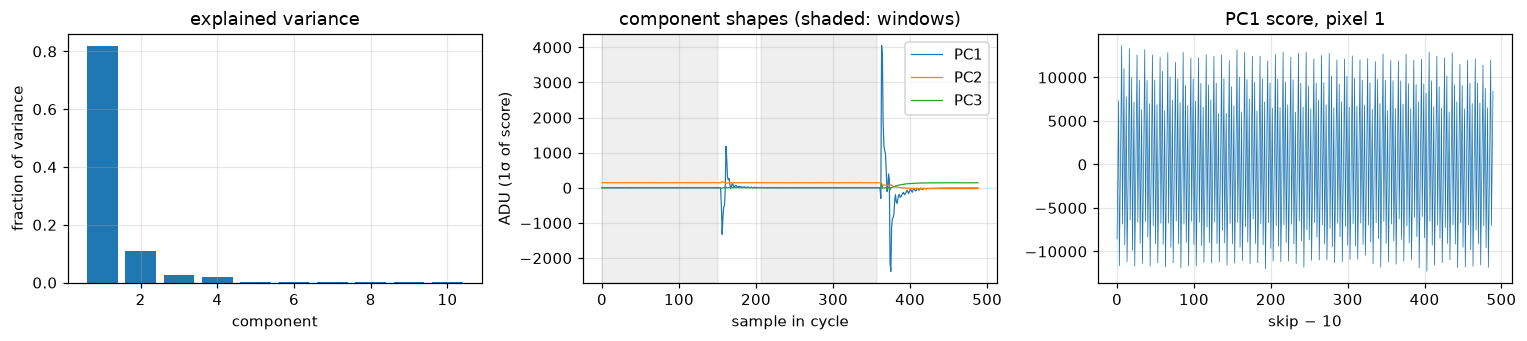

variance fraction of PC1-5: [0.819 0.11  0.028 0.019 0.001]
PC1 score autocorrelation, lags 1-3: [-0.27 -0.46  0.46]


In [25]:
R_all = np.vstack([residual_cycles(p) for p in GOOD])
U, s, Vt = np.linalg.svd(R_all - R_all.mean(0), full_matrices=False)
explained = s**2 / np.sum(s**2)
fig, ax = plt.subplots(1, 3, figsize=(14, 3.2))
ax[0].bar(np.arange(1, 11), explained[:10]); ax[0].set(xlabel="component", ylabel="fraction of variance", title="explained variance")
for i in range(3):
    ax[1].plot(Vt[i] * s[i] / np.sqrt(len(R_all)), lw=0.8, label=f"PC{i + 1}")
for a, b in ((0, N_PED), (SIG, SIG + N_PED)):
    ax[1].axvspan(a, b, color="gray", alpha=0.12)
ax[1].set(xlabel="sample in cycle", ylabel="ADU (1σ of score)", title="component shapes (shaded: windows)"); ax[1].legend()
scores = U[:, 0].reshape(len(GOOD), -1)[0] * s[0]
ax[2].plot(scores, lw=0.5); ax[2].set(xlabel="skip − 10", title=f"PC1 score, pixel {GOOD[0]}")
plt.tight_layout(); plt.show()
print("variance fraction of PC1-5:", np.round(explained[:5], 3))
print("PC1 score autocorrelation, lags 1-3:", np.round(acf(scores, 3), 2))

In this trace **PC1 (82 % of the variance) is the phase walk**: its shape is large only at the two
edges, with the derivative-like form of a time shift, and its score alternates from skip to skip. It
lies outside the windows, so the CDS ignores it. PC2 is nearly flat: the level shift set at each reset
(B4), which the CDS cancels. The components after that carry the much smaller variation that does
reach the CDS.

---
# F. Which features separate amplifiers better than repeats?

All scalar features above are computed, by one function, on:

* the 4 healthy repeats of channel 0 (the damaged repeat is skipped);
* the 5 repeats of channel 3 (another amplifier, same settings).

**Separation = |mean(ch0) − mean(ch3)| / run-to-run spread** (pooled standard deviation of the
repeats). The same test was applied to the 39 existing tools.

* A feature that does **not** separate two amplifiers (separation < 3) is either very stable across
  amplifiers or swamped by its own repeat scatter. It is less likely to see a parameter change.
* A large separation shows the feature is precise and sensitive to the amplifier. Whether it also
  responds to the operating parameters, and to σe, λ or the gain, only the scan can show.

In [26]:
def scalar_features(path):
    # every scalar feature of sections A-E for one trace (returns None for a damaged trace)
    t = decode_trace(path)
    if t.quality_problems():
        return None
    r = split_regions(t); good = usable_pixels(r)
    Cm = np.array([r.cds[p] for p in range(r.n_pixels)], float)
    cyc = {p: r.skip[p].astype(float) for p in good}
    det = {p: detrend(Cm[p, 10:]) for p in good}
    st, _ = t.window_slices(); br = np.flatnonzero(np.diff(st) > 2 * r.period)
    starts_of = {p: st[a:b] for p, (a, b) in enumerate(zip(np.r_[0, br + 1], np.r_[br, len(st) - 1]))}
    def resid(p):
        Y = cyc[p][10:]; kk = np.arange(len(Y)); X = np.vander((kk - kk.mean()) / kk.std(), 5)
        coef, *_ = np.linalg.lstsq(X, Y, rcond=None); return Y - X @ coef
    res = {p: resid(p) for p in good}
    out = {}
    # A
    _, out["A common CDS rise (ADU)"] = common_pattern(Cm, good)
    rl = relative_levels(Cm, good)
    out["A pixel level spread (ADU)"] = robust_spread(np.array([rl[p][0] for p in good]))
    # B
    out["B CDS noise per skip (ADU)"] = np.mean([det[p].std() for p in good])
    out["B ACF lag 1"] = np.mean([acf(det[p], 2)[0] for p in good])
    out["B ACF lag 2"] = np.mean([acf(det[p], 2)[1] for p in good])
    out["B Allan dev. n=50 (ADU)"] = np.mean([allan_deviation(det[p], [50])[0] for p in good])
    f_c, S_c = cds_spectrum(list(det.values()), SKIP_RATE)
    out["B CDS power <1 kHz / >10 kHz"] = S_c[(f_c > 0) & (f_c < 1e3)].mean() / S_c[f_c > 10e3].mean()
    out["B reset-level scatter (ADU)"] = np.mean([res[p][:, :r.n_ped].mean(1).std() for p in good])
    seg = r.sig_start + r.n_ped
    inside = [res[p][:, :seg] - res[p][:, :seg].mean(1, keepdims=True) for p in good]
    S_i = np.mean([np.mean(np.abs(np.fft.rfft(x * np.hanning(seg), axis=1)) ** 2, 0) for x in inside], 0)
    f_i = np.fft.rfftfreq(seg, 1 / SAMPLE_RATE_HZ)
    out["B within-cycle power 3-7.5 MHz fraction"] = S_i[f_i >= 3e6].sum() / S_i[f_i >= 0.1e6].sum()
    def reint(p, L):
        Y = cyc[p]; c = Y[:, :L].mean(1) - Y[:, r.sig_start:r.sig_start + L].mean(1); return detrend(c[10:]).std()
    out["B noise ratio L75/L150"] = np.mean([reint(p, 75) / reint(p, 150) for p in good])
    sig_shape = np.mean([(w := cyc[p][10:, r.sig_start:r.sig_start + r.n_ped]) .mean(0) - w.mean() for p in good], 0)
    out["B signal-window settling (ADU)"] = sig_shape[-10:].mean() - sig_shape[:10].mean()
    out["B baseline coupling (1e-3)"] = 1e3 * np.mean([np.polyfit(cyc[p][10:, :r.n_ped].mean(1), Cm[p, 10:], 1)[0] for p in good])
    # C
    out["C excess kurtosis"] = np.mean([outlier_stats(det[p])[1] for p in good])
    out["C largest CDS step (t)"] = np.mean([largest_step(det[p])[1] for p in good])
    # D
    jit = []
    for p in good:
        e = edge_times(cyc[p], starts_of[p]); kk = np.arange(len(e)); fit = np.polyfit(kk[5:], e[5:], 1)
        jit.append((e - np.polyval(fit, kk))[5:].std())
    out["D edge jitter (ns)"] = np.mean(jit) / SAMPLE_RATE_HZ * 1e9
    ft = np.array([feedthrough(cyc[p], r.n_ped, r.sig_start) for p in good])
    out["D dip per volt SW (ADU/V)"] = ft[:, 0].mean() / sw_swing
    out["D pulse per volt RG (ADU/V)"] = ft[:, 1].mean() / rg_swing
    out["D pulse/dip ratio"] = ft[:, 1].mean() / ft[:, 0].mean()
    # E
    rs = row_start_pixels(r)[1]
    dd = r.skip[rs][:, :r.n_ped].mean(1) - r.skip[rs + 1][:, :r.n_ped].mean(1)
    out["E row-start recovery (skips)"] = fit_exponential(np.arange(len(dd), dtype=float), dd, 2, 2000)[0]
    H = np.array([(h := r.h[p].astype(float) - r.h[p][:, :30].mean(1, keepdims=True)).max(1) - h.min(1) for p in good])
    out["E H-transfer peak-to-peak (ADU)"] = H.mean()
    Rm = np.vstack(list(res.values())); sv = np.linalg.svd(Rm - Rm.mean(0), compute_uv=False)
    out["E PC1 variance fraction"] = sv[0] ** 2 / np.sum(sv ** 2)
    return out

feats = {ch: [f for f in (scalar_features(p) for p in traces_of(ch)) if f] for ch in (0, 3)}
names = list(feats[0][0])
table = []
for name in names:
    a = np.array([f[name] for f in feats[0]]); b = np.array([f[name] for f in feats[3]])
    spread = np.sqrt((a.var(ddof=1) * (len(a) - 1) + b.var(ddof=1) * (len(b) - 1)) / (len(a) + len(b) - 2))
    table.append((name, a.mean(), a.std(ddof=1), b.mean(), b.std(ddof=1), abs(a.mean() - b.mean()) / spread))
print(f"{len(feats[0])} ch0 repeats, {len(feats[3])} ch3 repeats\n")
print(f"{'feature':40s} {'ch0 mean ± sd':>22s} {'ch3 mean ± sd':>22s} {'separation':>10s}")
for name, ma, sa, mb, sb, sep in table:
    print(f"{name:40s} {ma:12.4g} ± {sa:<8.2g} {mb:12.4g} ± {sb:<8.2g} {sep:10.1f}")

4 ch0 repeats, 5 ch3 repeats

feature                                           ch0 mean ± sd          ch3 mean ± sd separation
A common CDS rise (ADU)                         28.95 ± 0.42            26.24 ± 0.72            4.5
A pixel level spread (ADU)                      11.79 ± 11              612.4 ± 1.2e+03         0.6
B CDS noise per skip (ADU)                      5.548 ± 0.092           6.628 ± 0.18            7.4
B ACF lag 1                                   0.07124 ± 0.013         0.04158 ± 0.014           2.2
B ACF lag 2                                   -0.1795 ± 0.019         -0.1332 ± 0.026           2.0
B Allan dev. n=50 (ADU)                        0.6652 ± 0.041           0.971 ± 0.087           4.3
B CDS power <1 kHz / >10 kHz                   0.9622 ± 0.11            1.076 ± 0.15            0.9
B reset-level scatter (ADU)                     143.6 ± 2.3               138 ± 2.3             2.4
B within-cycle power 3-7.5 MHz fraction        0.2115 ± 0.0014         0

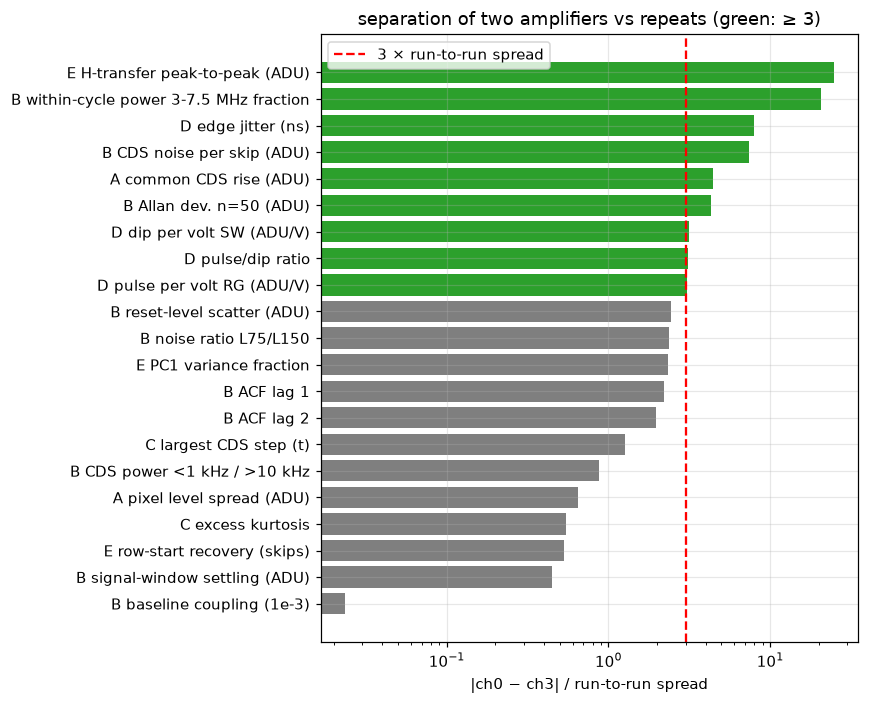

In [27]:
order = np.argsort([t[5] for t in table])
seps = np.array([table[i][5] for i in order])
fig, ax = plt.subplots(figsize=(8, 6.5))
ax.barh([table[i][0] for i in order], seps, color=["tab:green" if v >= 3 else "tab:gray" for v in seps])
ax.axvline(3, color="r", ls="--", label="3 × run-to-run spread")
ax.set_xscale("log"); ax.set(xlabel="|ch0 − ch3| / run-to-run spread", title="separation of two amplifiers vs repeats (green: ≥ 3)")
ax.legend(); plt.tight_layout(); plt.show()

**Results of the test on these 9 traces:**

* **Clearly separating (≥ 3):**
  * within-cycle power fraction at 3–7.5 MHz (~21);
  * horizontal-transfer amplitude (~25);
  * edge jitter (~8);
  * CDS noise per skip (~7);
  * common CDS rise and Allan deviation at n = 50 (~4);
  * feedthrough per volt and their ratio (~3).

  These are precise, amplifier-specific numbers, the best candidates to also see parameter changes.
* **Same on both amplifiers:** the baseline coupling is identical (2.11 × 10⁻³) on both channels,
  with a small scatter. If it moves with θ, it is a clean parameter signal that does not depend on
  the amplifier.
* **Too variable between repeats on these data:** the pixel-level spread (the charge in the pixels
  changed between back-to-back runs, as seen on 10-08), the signal-window settling and row-start
  recovery on channel 3, the steps and the kurtosis. They may still respond to θ, but they need more
  repeats, or a controlled state (the flushes before every trace set in the new packet help with
  the charge).

This is only 4 + 5 traces of one session. The packets' 3 + 3 trace sets will measure the run-to-run
scatter of every feature in every packet.

### What a model would receive

For every trace set in a packet, the features above form one row: the scalars as numbers, and the
curves (autocorrelation, Allan deviation, spectra, noise against window length, variation along the
cycle, component shapes) as fixed-length vectors. Per packet and channel, the model gets:

* the mean over the 3 trace sets at θ, and the same at the reference;
* the difference θ − reference, which removes most of the amplifier's fixed signature;
* the scatter between the 3 sets, which tells the model how much to trust each feature;
* θ itself, and the image labels (σe, λ, gain from WADERs) as targets.

Here is the feature row of the trace used throughout this notebook:

In [28]:
row = scalar_features(PATH)
for name, value in row.items():
    print(f"{name:40s} {value:12.5g}")

A common CDS rise (ADU)                        29.133
A pixel level spread (ADU)                     3.0641
B CDS noise per skip (ADU)                     5.6173
B ACF lag 1                                  0.060845
B ACF lag 2                                  -0.19879
B Allan dev. n=50 (ADU)                       0.65499
B CDS power <1 kHz / >10 kHz                    1.045
B reset-level scatter (ADU)                    146.57
B within-cycle power 3-7.5 MHz fraction       0.21053
B noise ratio L75/L150                         1.2193
B signal-window settling (ADU)                 123.75
B baseline coupling (1e-3)                     2.1092
C excess kurtosis                             0.11178
C largest CDS step (t)                         2.7389
D edge jitter (ns)                             1.7371
D dip per volt SW (ADU/V)                     -1921.3
D pulse per volt RG (ADU/V)                      7755
D pulse/dip ratio                             -3.4598
E row-start recovery (skips)

## Summary

| section | features (numbers; curves) | possible link |
|---|---|---|
| A1 | common CDS rise; common pattern | output-stage operating point |
| A2 | spread and max of the pixel levels | charge in the pixels → λ |
| A3 | charge-loss slope and skewness (charged pixels only) | SW/OG levels and timing |
| B1–B3 | ACF lags, Allan σ at n, low/high CDS power; the curves | how noise averages down → σe |
| B4 | reset-level scatter, within-cycle band powers | sense node (kTC), noise source in the chain |
| B5 | σ(75)/σ(150); noise against window length | `delayInt`, window placement |
| B6 | settling across each window | clock delays, amplifier speed |
| B7 | baseline coupling; noise along the skips | output-stage biases |
| C1–C4 | largest step, kurtosis, outlier fraction, lines, ADC χ² | discrete noise, interference, ADC health |
| D1–D3 | jitter, rise time, recovery time constants, residual oscillation | clock and amplifier bandwidth |
| D4 | dip and pulse per volt, their ratio | coupling × amplification (gain-related?) |
| D5 | variation along the cycle | where the skip-to-skip variation lives |
| E1–E4 | row-start recovery, drift, H-transfer amplitude, PC variance fractions | vertical/horizontal clocks, unnamed shapes |

Next steps, if you agree:

1. Choose the features to keep, guided by section F and by whether they are cheap and robust.
2. Put them in `src/trace_features.py` and call it from `process_packet.py`, so every packet's 6
   trace sets get them, with their run-to-run scatter.
3. Use the first real scan to see which features move with θ and with the image labels.